<a href="https://colab.research.google.com/github/Nihar16/Personal-Repository/blob/main/Pishing_Detection.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## **URL Pishing Detection**

In [1]:
import pandas as pd # use for data manipulation and analysis
import numpy as np # use for multi-dimensional array and matrix
!pip install selenium
import seaborn as sns # use for high-level interface for drawing attractive and informative statistical graphics
import matplotlib.pyplot as plt # It provides an object-oriented API for embedding plots into applications
%matplotlib inline
# It sets the backend of matplotlib to the 'inline' backend:
import plotly.express as px
import time # calculate time

from sklearn.linear_model import LogisticRegression # algo use to predict good or bad
from sklearn.naive_bayes import MultinomialNB # nlp algo use to predict good or bad

from sklearn.model_selection import train_test_split # spliting the data between feature and target
from sklearn.metrics import classification_report # gives whole report about metrics (e.g, recall,precision,f1_score,c_m)
from sklearn.metrics import confusion_matrix # gives info about actual and predict
from nltk.tokenize import RegexpTokenizer # regexp tokenizers use to split words from text
from nltk.stem.snowball import SnowballStemmer # stemmes words
from sklearn.feature_extraction.text import CountVectorizer # create sparse matrix of words using regexptokenizes
from sklearn.pipeline import make_pipeline # use for combining all prerocessors techniuqes and algos
from PIL import Image # getting images in notebook
from wordcloud import WordCloud, STOPWORDS, ImageColorGenerator# creates words colud

from bs4 import BeautifulSoup # use for scraping the data from website
from selenium import webdriver # use for automation chrome
import networkx as nx # for the creation, manipulation, and study of the structure, dynamics, and functions of complex networks.

import pickle# use to dump model

import warnings # ignores pink warnings
warnings.filterwarnings('ignore')

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.8/11.8 MB 82.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 511.8/511.8 kB 17.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 135.7/135.7 kB 10.0 MB/s eta 0:00:00
  Attempting uninstall: urllib3
    Found existing installation: urllib3 2.5.0
    Uninstalling urllib3-2.5.0:
      Successfully uninstalled urllib3-2.5.0


In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
# Load Dataset
phish_data = pd.read_csv('/content/drive/MyDrive/ColabNotebooks/MastersProject/url spam.csv')
phish_data.head()

,URL,Label
0,nobell.it/70ffb52d079109dca5664cce6f317373782/...,bad
1,www.dghjdgf.com/paypal.co.uk/cycgi-bin/webscrc...,bad
2,serviciosbys.com/paypal.cgi.bin.get-into.herf....,bad
3,mail.printakid.com/www.online.americanexpress....,bad
4,thewhiskeydregs.com/wp-content/themes/widescre...,bad


In [4]:
phish_data.tail()

,URL,Label
549341,23.227.196.215/,bad
549342,apple-checker.org/,bad
549343,apple-iclods.org/,bad
549344,apple-uptoday.org/,bad
549345,apple-search.info,bad


In [5]:
phish_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 549346 entries, 0 to 549345
Data columns (total 2 columns):
 #   Column  Non-Null Count   Dtype 
---  ------  --------------   ----- 
 0   URL     549346 non-null  object
 1   Label   549346 non-null  object
dtypes: object(2)
memory usage: 8.4+ MB


In [6]:
phish_data.isnull().sum()

,0
URL,0
Label,0


In [7]:
#create a dataframe of classes counts
label_counts = pd.DataFrame(phish_data.Label.value_counts())
#visualizing target_column
label_counts = pd.DataFrame(phish_data.Label.value_counts())
print(label_counts)

        count
Label        
good   392924
bad    156422


In [8]:
#create a dataframe of classes counts
label_counts = pd.DataFrame(phish_data.Label.value_counts())
#visualizing target_col
fig = px.bar(label_counts, x=label_counts.index, y='count') # Use 'count' as the y-axis
fig.show()

In [9]:
tokenizer = RegexpTokenizer(r'[A-Za-z]+')#to getting alpha only

In [10]:
# this will be pull letter which matches to expression
tokenizer = RegexpTokenizer(r'\w+')
tokenizer.tokenize(phish_data.URL[0]) # using first row

['nobell',
 'it',
 '70ffb52d079109dca5664cce6f317373782',
 'login',
 'SkyPe',
 'com',
 'en',
 'cgi',
 'bin',
 'verification',
 'login',
 '70ffb52d079109dca5664cce6f317373',
 'index',
 'php',
 'cmd',
 '_profile',
 'ach',
 'outdated_page_tmpl',
 'p',
 'gen',
 'failed',
 'to',
 'load',
 'nav',
 '0',
 '5',
 '1',
 'login_access',
 '1322408526']

In [11]:
# this will be pull letter which matches to expression
tokenizer = RegexpTokenizer(r'\w+')
tokenizer.tokenize(phish_data.URL[1])

['www',
 'dghjdgf',
 'com',
 'paypal',
 'co',
 'uk',
 'cycgi',
 'bin',
 'webscrcmd',
 '_home',
 'customer',
 'nav',
 '1',
 'loading',
 'php']

In [12]:
# this will be pull letter which matches to expression
tokenizer = RegexpTokenizer(r'\w+')
tokenizer.tokenize(phish_data.URL[2])

['serviciosbys',
 'com',
 'paypal',
 'cgi',
 'bin',
 'get',
 'into',
 'herf',
 'secure',
 'dispatch35463256rzr321654641dsf654321874',
 'href',
 'href',
 'href',
 'secure',
 'center',
 'update',
 'limit',
 'seccure',
 '4d7a1ff5c55825a2e632a679c2fd5353']

In [13]:
print('Getting words tokenized ...')
t0= time.perf_counter()
phish_data['text_tokenized'] = phish_data.URL.map(lambda t: tokenizer.tokenize(t)) # doing with all rows
t1 = time.perf_counter() - t0
print('Time taken',t1 ,'sec')

Getting words tokenized ...
Time taken 1.9200029529999938 sec


In [14]:
phish_data.sample(5)

,URL,Label,text_tokenized
365815,jjbillion.com/sc/,good,"[jjbillion, com, sc]"
355179,houseofnames.com/patry-family-crest,good,"[houseofnames, com, patry, family, crest]"
442997,thaiexpress.ca/about-us/,good,"[thaiexpress, ca, about, us]"
206625,laughstore.stores.yahoo.net/lillytomlin.html,good,"[laughstore, stores, yahoo, net, lillytomlin, ..."
120928,tienditabodhi.cl/casts,bad,"[tienditabodhi, cl, casts]"


In [15]:
stemmer = SnowballStemmer("english") # choose a language
print('Getting words stemmed ...')
t0= time.perf_counter()
phish_data['text_stemmed'] = phish_data['text_tokenized'].map(lambda l: [stemmer.stem(word) for word in l])
t1= time.perf_counter() - t0
print('Time taken',t1 ,'sec')

Getting words stemmed ...
Time taken 32.12545968300003 sec


In [16]:
print('Getting joiningwords ...')
t0= time.perf_counter()
phish_data['text_sent'] = phish_data['text_stemmed'].map(lambda l: ' '.join(l))
t1= time.perf_counter() - t0
print('Time taken',t1 ,'sec')

Getting joiningwords ...
Time taken 0.19716827599995668 sec


In [17]:
phish_data.sample(7)

,URL,Label,text_tokenized,text_stemmed,text_sent
126037,ysgrp.com.cn/js?http://us.battle.net/login/en/...,bad,"[ysgrp, com, cn, js, http, us, battle, net, lo...","[ysgrp, com, cn, js, http, us, battl, net, log...",ysgrp com cn js http us battl net login en ref...
393299,mp3raid.com/music/love_lockdown.html,good,"[mp3raid, com, music, love_lockdown, html]","[mp3raid, com, music, love_lockdown, html]",mp3raid com music love_lockdown html
427590,scarletknights.com/basketball-men/news/release...,good,"[scarletknights, com, basketball, men, news, r...","[scarletknight, com, basketbal, men, news, rel...",scarletknight com basketbal men news releas as...
56865,www.technica.net/NF/NF2/ejapanPP.htm,good,"[www, technica, net, NF, NF2, ejapanPP, htm]","[www, technica, net, nf, nf2, ejapanpp, htm]",www technica net nf nf2 ejapanpp htm
333719,fairfaxcounty.gov/,good,"[fairfaxcounty, gov]","[fairfaxcounti, gov]",fairfaxcounti gov
166768,dryangacupuncture.com/dr-yangs-specialties/doe...,good,"[dryangacupuncture, com, dr, yangs, specialtie...","[dryangacupunctur, com, dr, yang, specialti, d...",dryangacupunctur com dr yang specialti doe acu...
219205,myshadesmagazine.net/,good,"[myshadesmagazine, net]","[myshadesmagazin, net]",myshadesmagazin net


In [18]:
phish_data.sample(7)

,URL,Label,text_tokenized,text_stemmed,text_sent
448470,top-law-schools.com/ocu-school-of-law.html,good,"[top, law, schools, com, ocu, school, of, law,...","[top, law, school, com, ocu, school, of, law, ...",top law school com ocu school of law html
170000,en.wikipedia.org/wiki/1951_NAIA_Men%27s_Divisi...,good,"[en, wikipedia, org, wiki, 1951_NAIA_Men, 27s_...","[en, wikipedia, org, wiki, 1951_naia_men, 27s_...",en wikipedia org wiki 1951_naia_men 27s_divisi...
348114,greatschools.org/indiana/new-haven/,good,"[greatschools, org, indiana, new, haven]","[greatschool, org, indiana, new, haven]",greatschool org indiana new haven
124931,cbtechrepairs.com/www.dropbox.com/o/,bad,"[cbtechrepairs, com, www, dropbox, com, o]","[cbtechrepair, com, www, dropbox, com, o]",cbtechrepair com www dropbox com o
237524,screenwriterstoolkit.com/,good,"[screenwriterstoolkit, com]","[screenwriterstoolkit, com]",screenwriterstoolkit com
378482,livescorealerts.com/ireland-soccer/northern-ir...,good,"[livescorealerts, com, ireland, soccer, northe...","[livescorealert, com, ireland, soccer, norther...",livescorealert com ireland soccer northern ire...
136094,hubclone-sox.rhcloud.com/facebook3/,bad,"[hubclone, sox, rhcloud, com, facebook3]","[hubclon, sox, rhcloud, com, facebook3]",hubclon sox rhcloud com facebook3


In [19]:
# Visualize important keys using word cloud
#sliceing classes
bad_sites = phish_data[phish_data.Label == 'bad']
good_sites = phish_data[phish_data.Label == 'good']
bad_sites.head()

,URL,Label,text_tokenized,text_stemmed,text_sent
0,nobell.it/70ffb52d079109dca5664cce6f317373782/...,bad,"[nobell, it, 70ffb52d079109dca5664cce6f3173737...","[nobel, it, 70ffb52d079109dca5664cce6f31737378...",nobel it 70ffb52d079109dca5664cce6f317373782 l...
1,www.dghjdgf.com/paypal.co.uk/cycgi-bin/webscrc...,bad,"[www, dghjdgf, com, paypal, co, uk, cycgi, bin...","[www, dghjdgf, com, paypal, co, uk, cycgi, bin...",www dghjdgf com paypal co uk cycgi bin webscrc...
2,serviciosbys.com/paypal.cgi.bin.get-into.herf....,bad,"[serviciosbys, com, paypal, cgi, bin, get, int...","[serviciosbi, com, paypal, cgi, bin, get, into...",serviciosbi com paypal cgi bin get into herf s...
3,mail.printakid.com/www.online.americanexpress....,bad,"[mail, printakid, com, www, online, americanex...","[mail, printakid, com, www, onlin, americanexp...",mail printakid com www onlin americanexpress c...
4,thewhiskeydregs.com/wp-content/themes/widescre...,bad,"[thewhiskeydregs, com, wp, content, themes, wi...","[thewhiskeydreg, com, wp, content, theme, wide...",thewhiskeydreg com wp content theme widescreen...


In [20]:
good_sites.head()

,URL,Label,text_tokenized,text_stemmed,text_sent
18231,esxcc.com/js/index.htm?us.battle.net/noghn/en/...,good,"[esxcc, com, js, index, htm, us, battle, net, ...","[esxcc, com, js, index, htm, us, battl, net, n...",esxcc com js index htm us battl net noghn en r...
18232,wwweira¯&nvinip¿ncH¯wVö%ÆåyDaHðû/ÏyEùuË\nÓ6...,good,"[www, eira, nvinip, ncH, wVö, ÆåyDaHðû, ÏyEùu,...","[www, eira, nvinip, nch, wvö, æåydahðû, ïyeùu,...",www eira nvinip nch wvö æåydahðû ïyeùu ë ó 6 r...
18233,'www.institutocgr.coo/web/media/syqvem/dk-óij...,good,"[www, institutocgr, coo, web, media, syqvem, d...","[www, institutocgr, coo, web, media, syqvem, d...",www institutocgr coo web media syqvem dk óij r...
18234,Yìê koãÕ»Î§DéÎl½ñ¡ââqtò¸/à; Í,good,"[Yìê, koãÕ, Î, DéÎ, l½ñ, ââqtò, à, Í]","[yìê, koãõ, î, déî, l½ñ, ââqtò, à, í]",yìê koãõ î déî l½ñ ââqtò à í
18236,ruta89fm.com/images/AS@Vies/1i75cf7b16vc<Fd16...,good,"[ruta89fm, com, images, AS, Vies, 1i75cf7b16vc...","[ruta89fm, com, imag, as, vie, 1i75cf7b16vc, f...",ruta89fm com imag as vie 1i75cf7b16vc f d16b96...


In [21]:
def plot_wordcloud(text, mask=None, max_words=400, max_font_size=120, figure_size=(24.0,16.0),
                   title = None, title_size=40, image_color=False):
    stopwords = set(STOPWORDS)
    more_stopwords = {'com','http'}
    stopwords = stopwords.union(more_stopwords)

    wordcloud = WordCloud(background_color='white',
                    stopwords = stopwords,
                    max_words = max_words,
                    max_font_size = max_font_size,
                    random_state = 42,
                    mask = mask)
    wordcloud.generate(text)

    plt.figure(figsize=figure_size)
    if image_color:
        image_colors = ImageColorGenerator(mask);
        plt.imshow(wordcloud.recolor(color_func=image_colors), interpolation="bilinear");
        plt.title(title, fontdict={'size': title_size,
                                  'verticalalignment': 'bottom'})
    else:
        plt.imshow(wordcloud);
        plt.title(title, fontdict={'size': title_size, 'color': 'green',
                                  'verticalalignment': 'bottom'})
    plt.axis('off');
    plt.tight_layout()
d = '../input/masks/masks-wordclouds/'

In [22]:
#create cv object
cv = CountVectorizer()
#help(CountVectorizer())

In [23]:
# Check the column names in the DataFrame
print(phish_data.columns)

# Assuming the correct column name is 'URL', use the following:
feature = cv.fit_transform(phish_data.URL)

# If the column name is different, replace 'URL' with the actual name

Index(['URL', 'Label', 'text_tokenized', 'text_stemmed', 'text_sent'], dtype='object')


In [24]:
feature[:5].toarray()

array([[0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0]])

In [25]:
# Splitting data
trainX, testX, trainY, testY = train_test_split(feature, phish_data.Label)

In [26]:
# Logistic Regression
lr = LogisticRegression()
lr.fit(trainX,trainY)
lr.score(testX,testY)

0.9634912660098881

In [27]:
# Generate confusion matrix for Logistic Regression
lr_predictions = lr.predict(testX)  # Predictions on the test set
lr_cm = confusion_matrix(testY, lr_predictions)  # Confusion matrix

# Display the confusion matrix
print("Confusion Matrix for Logistic Regression:")
print(lr_cm)

Confusion Matrix for Logistic Regression:
[[34767  4013]
 [ 1001 97556]]


In [28]:
Scores_ml = {}
Scores_ml['Logistic Regression'] = np.round(lr.score(testX,testY),2)

Training Accuracy : 0.9800441252496912
Testing Accuracy : 0.9634912660098881

CLASSIFICATION REPORT

              precision    recall  f1-score   support

         Bad       0.90      0.97      0.93     35768
        Good       0.99      0.96      0.97    101569

    accuracy                           0.96    137337
   macro avg       0.94      0.97      0.95    137337
weighted avg       0.97      0.96      0.96    137337


CONFUSION MATRIX


<Axes: >

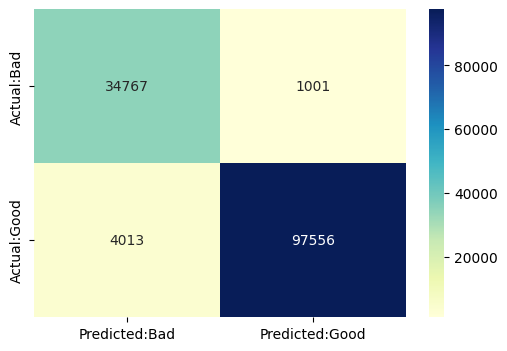

In [29]:
print('Training Accuracy :',lr.score(trainX,trainY))
print('Testing Accuracy :',lr.score(testX,testY))
con_mat = pd.DataFrame(confusion_matrix(lr.predict(testX), testY),
            columns = ['Predicted:Bad', 'Predicted:Good'],
            index = ['Actual:Bad', 'Actual:Good'])


print('\nCLASSIFICATION REPORT\n')
print(classification_report(lr.predict(testX), testY,
                            target_names =['Bad','Good']))

print('\nCONFUSION MATRIX')
plt.figure(figsize= (6,4))
sns.heatmap(con_mat, annot = True,fmt='d',cmap="YlGnBu")

In [30]:
# Create MultinomialNB Object
mnb = MultinomialNB()
mnb.fit(trainX,trainY)
mnb.score(testX,testY)
mnb.score(testX,testY)

0.9632509811631242

In [31]:
# Generate confusion matrix for Multinomial Naive Bayes
mnb_predictions = mnb.predict(testX)
mnb_cm = confusion_matrix(testY, mnb_predictions)

# Display the confusion matrix
print("\nConfusion Matrix for Multinomial Naive Bayes:")
print(mnb_cm)


Confusion Matrix for Multinomial Naive Bayes:
[[36254  2526]
 [ 2521 96036]]


Training Accuracy : 0.983027069797019
Testing Accuracy : 0.9632509811631242

CLASSIFICATION REPORT

              precision    recall  f1-score   support

         Bad       0.93      0.93      0.93     38775
        Good       0.97      0.97      0.97     98562

    accuracy                           0.96    137337
   macro avg       0.95      0.95      0.95    137337
weighted avg       0.96      0.96      0.96    137337


CONFUSION MATRIX


<Axes: >

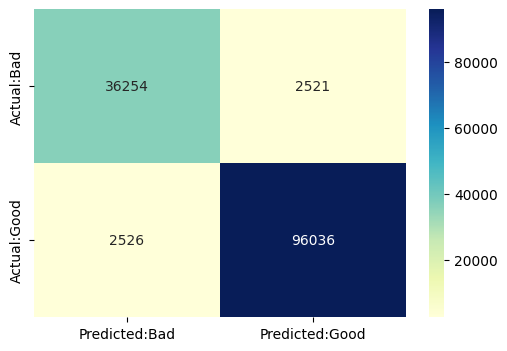

In [32]:
Scores_ml['MultinomialNB'] = np.round(mnb.score(testX,testY),2)
print('Training Accuracy :',mnb.score(trainX,trainY))
print('Testing Accuracy :',mnb.score(testX,testY))
con_mat = pd.DataFrame(confusion_matrix(mnb.predict(testX), testY),
            columns = ['Predicted:Bad', 'Predicted:Good'],
            index = ['Actual:Bad', 'Actual:Good'])


print('\nCLASSIFICATION REPORT\n')
print(classification_report(mnb.predict(testX), testY,
                            target_names =['Bad','Good']))

print('\nCONFUSION MATRIX')
plt.figure(figsize= (6,4))
sns.heatmap(con_mat, annot = True,fmt='d',cmap="YlGnBu")

<Axes: xlabel='None', ylabel='Accuracy'>

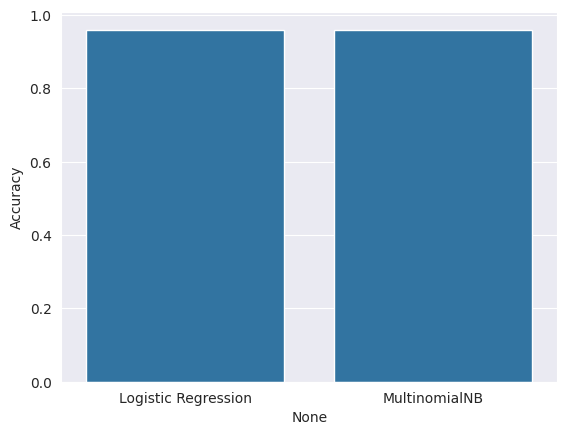

In [33]:
acc = pd.DataFrame.from_dict(Scores_ml,orient = 'index',columns=['Accuracy'])
sns.set_style('darkgrid')
sns.barplot(x=acc.index, y=acc.Accuracy) # Pass x and y as named arguments.

In [34]:
pipeline_ls = make_pipeline(CountVectorizer(tokenizer = RegexpTokenizer(r'[A-Za-z]+').tokenize,stop_words='english'), LogisticRegression())

In [35]:
trainX, testX, trainY, testY = train_test_split(phish_data.URL, phish_data.Label)
pipeline_ls.fit(trainX,trainY)

Pipeline(steps=[('countvectorizer',
                 CountVectorizer(stop_words='english',
                                 tokenizer=<bound method RegexpTokenizer.tokenize of RegexpTokenizer(pattern='[A-Za-z]+', gaps=False, discard_empty=True, flags=re.UNICODE|re.MULTILINE|re.DOTALL)>)),
                ('logisticregression', LogisticRegression())])

In [36]:
pipeline_ls.score(testX,testY)

0.9659742094264474

Training Accuracy : 0.9800125725408911
Testing Accuracy : 0.9659742094264474

CLASSIFICATION REPORT

              precision    recall  f1-score   support

         Bad       0.91      0.97      0.94     36864
        Good       0.99      0.97      0.98    100473

    accuracy                           0.97    137337
   macro avg       0.95      0.97      0.96    137337
weighted avg       0.97      0.97      0.97    137337


CONFUSION MATRIX


<Axes: >

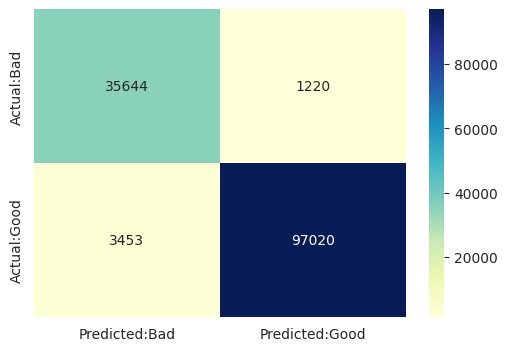

In [37]:
print('Training Accuracy :',pipeline_ls.score(trainX,trainY))
print('Testing Accuracy :',pipeline_ls.score(testX,testY))
con_mat = pd.DataFrame(confusion_matrix(pipeline_ls.predict(testX), testY),
            columns = ['Predicted:Bad', 'Predicted:Good'],
            index = ['Actual:Bad', 'Actual:Good'])


print('\nCLASSIFICATION REPORT\n')
print(classification_report(pipeline_ls.predict(testX), testY,
                            target_names =['Bad','Good']))

print('\nCONFUSION MATRIX')
plt.figure(figsize= (6,4))
sns.heatmap(con_mat, annot = True,fmt='d',cmap="YlGnBu")

In [38]:
pickle.dump(pipeline_ls,open('phishing.pkl','wb'))
loaded_model = pickle.load(open('phishing.pkl', 'rb'))
result = loaded_model.score(testX,testY)
print(result)

0.9659742094264474


In [39]:
# Load the trained model
loaded_model = pickle.load(open('phishing.pkl', 'rb'))

def predict_link(link):
    """Predicts whether a given link is good or bad."""
    result = loaded_model.predict([link])  # Input should be a list
    if result[0] == 'good':
        return 'Good Link'
    else:
        return 'Bad Link'

# Get user input
user_link = input("Enter a link to predict: ")

# Predict and display the result
prediction = predict_link(user_link)
print(prediction)

Enter a link to predict: www.pornhub.com
Good Link


# **Email Pishing Detection**

In [40]:
# The Libraries need to be imported
import numpy as np # Linear Algebra
import pandas as pd # Data processing, CSV files
!pip install selenium
!pip install wordcloud
from wordcloud import WordCloud, STOPWORDS
import matplotlib.pyplot as plt
from PIL import Image
import plotly.express as px
import plotly.graph_objects as go
import plotly.figure_factory as ff
import seaborn as sns
import matplotlib.pyplot as plt
%matplotlib inline
import plotly.express as px
import time
import os
import re
from google.colab import data_table
import string
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report
from sklearn.metrics import confusion_matrix
from nltk.tokenize import RegexpTokenizer
from nltk.stem.snowball import SnowballStemmer
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.pipeline import make_pipeline
from PIL import Image
from wordcloud import WordCloud, STOPWORDS, ImageColorGenerator
from bs4 import BeautifulSoup
from selenium import webdriver
import networkx as nx
import pickle
import warnings
warnings.filterwarnings('ignore')

In [41]:
df = pd.read_csv('/content/drive/MyDrive/ColabNotebooks/MastersProject/spam email.csv', encoding='latin-1')
df.head(7)

,v1,v2,Unnamed: 2,Unnamed: 3,Unnamed: 4
0,ham,"Go until jurong point, crazy.. Available only ...",NaN,NaN,NaN
1,ham,Ok lar... Joking wif u oni...,NaN,NaN,NaN
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,NaN,NaN,NaN
3,ham,U dun say so early hor... U c already then say...,NaN,NaN,NaN
4,ham,"Nah I don't think he goes to usf, he lives aro...",NaN,NaN,NaN
5,spam,FreeMsg Hey there darling it's been 3 week's n...,NaN,NaN,NaN
6,ham,Even my brother is not like to speak with me. ...,NaN,NaN,NaN


In [42]:
df.tail(7)

,v1,v2,Unnamed: 2,Unnamed: 3,Unnamed: 4
5565,ham,Huh y lei...,NaN,NaN,NaN
5566,spam,REMINDER FROM O2: To get 2.50 pounds free call...,NaN,NaN,NaN
5567,spam,This is the 2nd time we have tried 2 contact u...,NaN,NaN,NaN
5568,ham,Will Ì_ b going to esplanade fr home?,NaN,NaN,NaN
5569,ham,"Pity, * was in mood for that. So...any other s...",NaN,NaN,NaN
5570,ham,The guy did some bitching but I acted like i'd...,NaN,NaN,NaN
5571,ham,Rofl. Its true to its name,NaN,NaN,NaN


In [43]:
df.isnull().sum()

,0
v1,0
v2,0
Unnamed: 2,5522
Unnamed: 3,5560
Unnamed: 4,5566


In [44]:
print(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5572 entries, 0 to 5571
Data columns (total 5 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   v1          5572 non-null   object
 1   v2          5572 non-null   object
 2   Unnamed: 2  50 non-null     object
 3   Unnamed: 3  12 non-null     object
 4   Unnamed: 4  6 non-null      object
dtypes: object(5)
memory usage: 217.8+ KB
None


In [45]:
#Let's drop the non-relevant unnamed columns
df=df.drop(['Unnamed: 2', 'Unnamed: 3','Unnamed: 4'],axis=1)

# Renaming v1 & v2 as Category & Text
df=df.rename(columns={"v1":"Category","v2":"Text"})

#Sample post modifications
df.head()

,Category,Text
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


In [46]:
#Let's check the length of the dataset
print(" Total number of rows in the dataset are", len(df))

 Total number of rows in the dataset are 5572


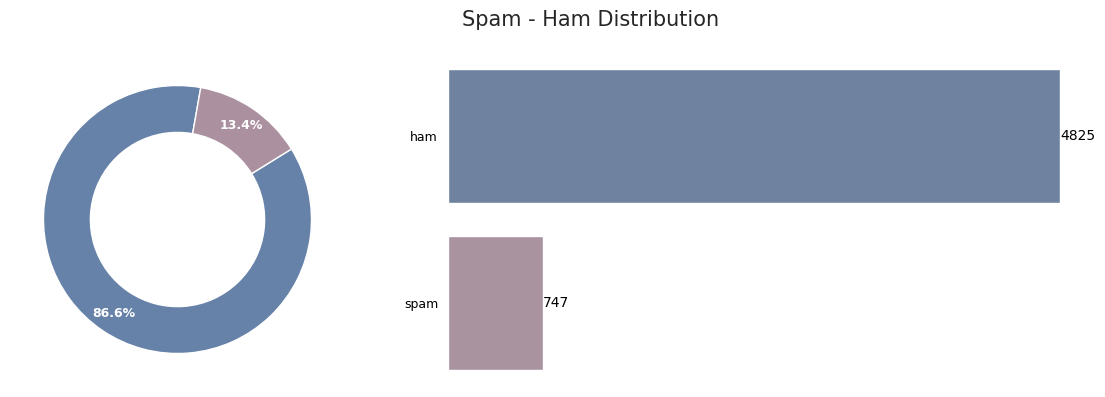

In [47]:
plt.rcParams['figure.facecolor'] = 'white'
plt.rcParams['axes.facecolor'] = 'white'
fig, ax = plt.subplots(1, 2, figsize=(15, 4))
ax = ax.flatten()
value_counts = df['Category'].value_counts()
labels = value_counts.index.tolist()
colors =["#6782a8", "#ab90a0" ]
# Donut Chart
wedges, texts, autotexts = ax[0].pie(
    value_counts, autopct='%1.1f%%',textprops={'size': 9, 'color': 'white','fontweight':'bold' }, colors=colors,
    wedgeprops=dict(width=0.35),  startangle=80,   pctdistance=0.85  )
# circle
centre_circle = plt.Circle((0, 0), 0.6, fc='white')
ax[0].add_artist(centre_circle)
# Count Plot
sns.countplot(data=df, y=df['Category'], ax=ax[1], palette=colors, order=labels)
for i, v in enumerate(value_counts):
    ax[1].text(v + 1, i, str(v), color='black',fontsize=10, va='center')
sns.despine(left=True, bottom=True)
plt.yticks(fontsize=9,color='black')
ax[1].set_ylabel(None)
plt.xlabel("")
plt.xticks([])
fig.suptitle('Spam - Ham Distribution', fontsize=15)
plt.tight_layout(rect=[0, 0, 0.85, 1])
plt.show()

In [48]:
#Descriptive Summary of the dataset
df.describe()

,Category,Text
count,5572,5572
unique,2,5169
top,ham,"Sorry, I'll call later"
freq,4825,30


In [49]:
#Let's create a column to check of each text & plot a histogram to check the distirbution
df['Length']=df['Text'].apply(len)
display(df.head())

#distribution of the data
import plotly.express as px
fig = px.histogram(df, x='Length', marginal='rug',
                   title='Histogram of Text Length')
fig.update_layout(
    xaxis_title='Length',
    yaxis_title='Frequency',
    showlegend=True)

,Category,Text,Length
0,ham,"Go until jurong point, crazy.. Available only ...",111
1,ham,Ok lar... Joking wif u oni...,29
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,155
3,ham,U dun say so early hor... U c already then say...,49
4,ham,"Nah I don't think he goes to usf, he lives aro...",61


In [50]:
#Lets check the distribution against categories
import plotly.express as px
fig = px.histogram(df, x='Length', color='Category', marginal='rug',
                   title='Histogram of Text Length by Category')
fig.update_layout(
    xaxis_title='Length',
    yaxis_title='Frequency',
    showlegend=True)

In [51]:
#Let's Label the data as 0 & 1 i.e. Spam as 1 & Ham as 0
df.loc[:,'Category']=df.Category.map({'ham':0, 'spam':1})
df['Category'] = df['Category'].astype(int)
df.head()

,Category,Text,Length
0,0,"Go until jurong point, crazy.. Available only ...",111
1,0,Ok lar... Joking wif u oni...,29
2,1,Free entry in 2 a wkly comp to win FA Cup fina...,155
3,0,U dun say so early hor... U c already then say...,49
4,0,"Nah I don't think he goes to usf, he lives aro...",61


In [52]:
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.model_selection import train_test_split

count = CountVectorizer()
text = count.fit_transform(df['Text'])
#Train & test split
x_train, x_test, y_train, y_test = train_test_split(text, df['Category'], test_size=0.30, random_state=100)
text

<Compressed Sparse Row sparse matrix of dtype 'int64'
	with 73916 stored elements and shape (5572, 8672)>

In [53]:
from sklearn.feature_extraction.text import CountVectorizer
import pickle
# Assuming 'df' is your DataFrame with the 'Text' column containing email text
vectorizer = CountVectorizer()
vectorizer.fit(df['Text'])
with open('email_vectorizer.pkl', 'wb') as f:
    pickle.dump(vectorizer, f)

In [54]:
#Let's print the dimentions of the train & test dataset
display('X-Train :', x_train.shape)
display('X-Test :',x_test.shape)
display('Y-Train :',y_train.shape)
display('X-Test :',y_test.shape)

'X-Train :'

(3900, 8672)

'X-Test :'

(1672, 8672)

'Y-Train :'

(3900,)

'X-Test :'

(1672,)

Confusion Matrix:
[[1441   18]
 [  13  200]]

Classification Report:
              precision    recall  f1-score   support

           0       0.99      0.99      0.99      1459
           1       0.92      0.94      0.93       213

    accuracy                           0.98      1672
   macro avg       0.95      0.96      0.96      1672
weighted avg       0.98      0.98      0.98      1672



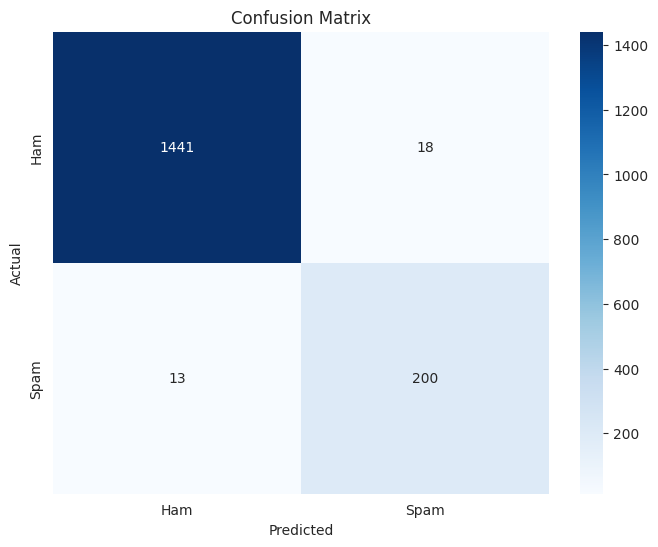

In [55]:
from sklearn.metrics import confusion_matrix, classification_report
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.naive_bayes import MultinomialNB #Import MultinomialNB

# Create a Multinomial Naive Bayes model
multinomial_nb_model = MultinomialNB()
multinomial_nb_model.fit(x_train, y_train)  # Train the model
prediction = multinomial_nb_model.predict(x_test) #Assign the prediction result to the prediction variable.

# Confusion Matrix
conf_matrix = confusion_matrix(y_test, prediction)
print("Confusion Matrix:")
print(conf_matrix)

# Classification Report
class_report = classification_report(y_test, prediction)
print("\nClassification Report:")
print(class_report)

# Plotting the Confusion Matrix (optional)
plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix, annot=True, fmt="d", cmap="Blues",
            xticklabels=['Ham', 'Spam'], yticklabels=['Ham', 'Spam'])
plt.title("Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

In [56]:
import pickle

# Save the trained model
filename = 'email_spam_model.pkl'
pickle.dump(multinomial_nb_model, open(filename, 'wb'))

# Load the saved model
loaded_model = pickle.load(open(filename, 'rb'))

# You can now use the loaded_model for predictions

In [57]:
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import MultinomialNB
import pickle

# ... (your previous code for loading data and splitting into x_train, x_test, y_train, y_test) ...

# Create and train the Multinomial Naive Bayes model
multinomial_nb_model = MultinomialNB()
multinomial_nb_model.fit(x_train, y_train)  # This is the missing step

# Save the trained model
filename = 'email_spam_model.pkl'
pickle.dump(multinomial_nb_model, open(filename, 'wb'))

# Load the saved model (this is now loading a trained model)
loaded_model = pickle.load(open(filename, 'rb'))


def predict_email(email_text):
    """Predicts whether a given email is spam or not."""
    email_text_vectorized = count.transform([email_text])
    prediction = loaded_model.predict(email_text_vectorized)[0]
    if prediction == 0:
        return 'Not Spam (Ham)'
    else:
        return 'Spam'


# Example usage:
user_email = input("Enter an email text to predict: ")
prediction = predict_email(user_email)
print(prediction)

Enter an email text to predict: www.8muses.com
Spam


# **SMS Pishing Detection**

In [58]:
# Cell 1: Importing libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import nltk
from nltk.corpus import stopwords
import re
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix, recall_score
import joblib
import os
import pickle
import warnings
warnings.filterwarnings('ignore')

In [59]:
df = pd.read_csv("/content/drive/MyDrive/ColabNotebooks/MastersProject/sms spam.csv", encoding="latin-1")
df = df[['v1', 'v2']]
df.columns = ['label', 'message']
df['label'] = df['label'].map({'spam': 1, 'ham': 0})
df.info()
df.head()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5572 entries, 0 to 5571
Data columns (total 2 columns):
 #   Column   Non-Null Count  Dtype 
---  ------   --------------  ----- 
 0   label    5572 non-null   int64 
 1   message  5572 non-null   object
dtypes: int64(1), object(1)
memory usage: 87.2+ KB


,label,message
0,0,"Go until jurong point, crazy.. Available only ..."
1,0,Ok lar... Joking wif u oni...
2,1,Free entry in 2 a wkly comp to win FA Cup fina...
3,0,U dun say so early hor... U c already then say...
4,0,"Nah I don't think he goes to usf, he lives aro..."


In [60]:
nltk.download('stopwords')
stop_words = set(stopwords.words('english'))

def preprocess_text(text):
    text = text.lower()
    text = re.sub(r'\d+', '', text)
    text = re.sub(r'[^\w\s]', '', text)
    text = ' '.join([word for word in text.split() if word not in stop_words])
    return text

df['clean_message'] = df['message'].apply(preprocess_text)
df[['message', 'clean_message']].head()

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.


,message,clean_message
0,"Go until jurong point, crazy.. Available only ...",go jurong point crazy available bugis n great ...
1,Ok lar... Joking wif u oni...,ok lar joking wif u oni
2,Free entry in 2 a wkly comp to win FA Cup fina...,free entry wkly comp win fa cup final tkts st ...
3,U dun say so early hor... U c already then say...,u dun say early hor u c already say
4,"Nah I don't think he goes to usf, he lives aro...",nah dont think goes usf lives around though


In [61]:
# Feature Extraction
vectorizer = CountVectorizer()
X = vectorizer.fit_transform(df['clean_message'])
y = df['label']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print(X_train.shape, X_test.shape)

(4457, 8467) (1115, 8467)


In [62]:
# Cell 5: Train models
models = {
    "NaiveBayes": MultinomialNB().fit(X_train, y_train),
    "Logistic Regression": LogisticRegression(max_iter=1000).fit(X_train, y_train),
}


NaiveBayes Classification Report:
              precision    recall  f1-score   support

           0       0.98      0.98      0.98       965
           1       0.87      0.90      0.88       150

    accuracy                           0.97      1115
   macro avg       0.92      0.94      0.93      1115
weighted avg       0.97      0.97      0.97      1115



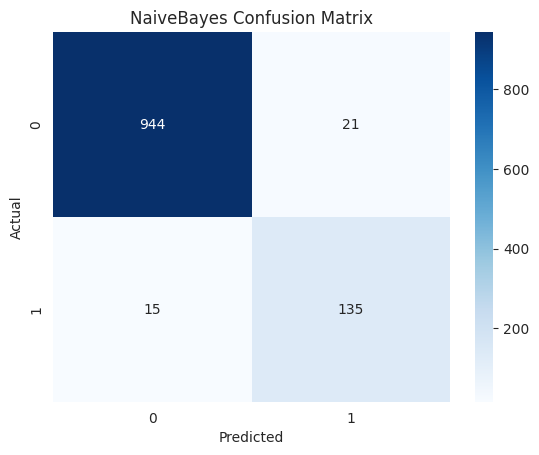


Logistic Regression Classification Report:
              precision    recall  f1-score   support

           0       0.97      1.00      0.99       965
           1       1.00      0.83      0.91       150

    accuracy                           0.98      1115
   macro avg       0.99      0.91      0.95      1115
weighted avg       0.98      0.98      0.98      1115



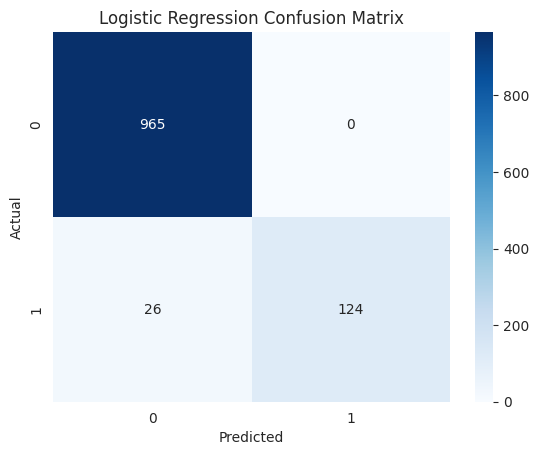

In [63]:
for name, model in models.items():
    y_pred = model.predict(X_test)
    print(f"\n{name} Classification Report:")
    print(classification_report(y_test, y_pred))
    cm = confusion_matrix(y_test, y_pred)
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
    plt.title(f"{name} Confusion Matrix")
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.show()

In [64]:
# Cell 7: Save and load the Naive Bayes model
nb_model = models["NaiveBayes"]
joblib.dump(nb_model, 'sms_spam_nb.pkl')
print("Model saved as 'sms_spam_nb.pkl'.")

if os.path.exists('sms_spam_nb.pkl'):
    loaded_model = joblib.load('sms_spam_nb.pkl')
    print("Model loaded successfully.")
else:
    print("Model file not found. Train and save the model first.")

Model saved as 'sms_spam_nb.pkl'.
Model loaded successfully.


In [65]:
# Feature Extraction
vectorizer = CountVectorizer()
X = vectorizer.fit_transform(df['clean_message'])
joblib.dump(nb_model, 'sms_spam_nb.pkl')
with open('sms_vectorizer.pkl', 'wb') as f:
    pickle.dump(vectorizer, f)

In [66]:
# Cell 8: Predict function
def predict_sms(sms_text):
    sms_text = preprocess_text(sms_text)
    feature_vector = vectorizer.transform([sms_text])
    prediction = loaded_model.predict(feature_vector)[0]
    return "Spam" if prediction == 1 else "Ham (Not Spam)"

user_sms = input("Enter the SMS text to predict: ")
print("Prediction:", predict_sms(user_sms))


Enter the SMS text to predict: www.8muses.com
Prediction: Ham (Not Spam)


# **Deep Fake Detection**

# **Flask App**

In [67]:
!pip install flask flask-ngrok
!pip install flask-cors

In [69]:
import os
from flask import Flask, request, jsonify, render_template, send_from_directory
from flask_cors import CORS
import joblib
import pickle
import re

app = Flask(__name__)
CORS(app)

# Load pre-trained models
try:
    email_model = pickle.load(open('content/email_spam_model.pkl', 'rb'))
    sms_model = joblib.load('content/sms_spam_nb.pkl')
    url_model = joblib.load('content/phishing.pkl')

    # Load vectorizers
    email_vectorizer = joblib.load('/content/email_vectorizer.pkl')
    sms_vectorizer = joblib.load('/content/sms_vectorizer.pkl')

    print("Models loaded successfully!")
except FileNotFoundError as fnfe:
    print(f"FileNotFoundError: {fnfe}")
    email_model = sms_model = url_model = vectorizer = None
except Exception as e:
    print(f"Error loading models: {e}")
    email_model = sms_model = url_model = vectorizer = None

UPLOAD_FOLDER = 'uploads'
if not os.path.exists(UPLOAD_FOLDER):
    os.makedirs(UPLOAD_FOLDER)
app.config['UPLOAD_FOLDER'] = UPLOAD_FOLDER


@app.route('/')
def index():
    return render_template('/content/drive/MyDrive/ColabNotebooks/MastersProject/template/index.html')  # Ensure 'index.html' is in the 'templates' directory


@app.route('/favicon.ico')
def favicon():
    return send_from_directory(
        os.path.join(app.root_path, 'static'),
        'favicon.ico',
        mimetype='image/vnd.microsoft.icon'
    )


@app.route('/analyze', methods=['POST'])
def analyze():
    detection_type = request.form.get('detectionType')
    input_text = request.form.get('inputText')

    if not detection_type or not input_text:
        return jsonify({"status": "error", "message": "Missing detection type or input text"})

    try:
        if detection_type == 'email':
            return analyze_email(input_text)
        elif detection_type == 'sms':
            return analyze_sms(input_text)
        elif detection_type == 'url':
            return analyze_url(input_text)
        else:
            return jsonify({"status": "error", "message": "Invalid detection type"})
    except Exception as e:
        print(f"Error in analyze function: {e}")
        return jsonify({"status": "error", "message": f"Failed to analyze {detection_type}"})


# Preprocessing function for all text types
def preprocess_text(text):
    """General text preprocessing function."""
    text = text.lower()
    text = re.sub(r'\W', ' ', text)  # Remove non-alphanumeric characters
    text = re.sub(r'\s+', ' ', text).strip()  # Normalize whitespace
    return text


def analyze_email(email_text):
    """Analyze email text for phishing."""
    try:
        # Preprocess the email text
        email_text = preprocess_text(email_text)
        reshaped_text = [email_text]  # Convert to list (1D array expected)

        # Debugging
        print(f"Input for email model: {reshaped_text}")

        # Predict using the email model
        prediction = email_model.predict(reshaped_text)[0]

        # Interpret model's output
        status = 'safe' if prediction == 0 else 'phishing'
        return jsonify({"status": "success", "prediction": status})
    except ValueError as ve:
        print(f"ValueError in analyze_email: {ve}")
        return jsonify({"status": "error", "message": f"Value error: {str(ve)}"})
    except Exception as e:
        print(f"Error in analyze_email: {e}")
        return jsonify({"status": "error", "message": "Failed to analyze email"})


def analyze_sms(sms_text):
    """Analyze SMS text for spam."""
    try:
        # Preprocess SMS text
        sms_text = preprocess_text(sms_text)
        feature_vector = vectorizer.transform([sms_text])  # Transform using the vectorizer

        # Debugging
        print(f"Feature vector for SMS: {feature_vector}")

        # Predict using the SMS model
        prediction = sms_model.predict(feature_vector)[0]
        status = "Spam" if prediction == 1 else "Ham (Not Spam)"
        return jsonify({"status": "success", "prediction": status})
    except Exception as e:
        print(f"Error in analyze_sms: {e}")
        return jsonify({"status": "error", "message": "Failed to analyze SMS"})


def analyze_url(url_text):
    """Analyze URL for phishing."""
    try:
        # Preprocess URL text
        url_text = preprocess_text(url_text)
        prediction = url_model.predict([url_text])[0]

        # Debugging
        print(f"Prediction for URL: {prediction}")

        # Interpret model's output
        status = 'safe' if prediction == 'good' else 'phishing'
        return jsonify({"status": "success", "prediction": status})
    except Exception as e:
        print(f"Error in analyze_url: {e}")
        return jsonify({"status": "error", "message": "Failed to analyze URL"})


if __name__ == '__main__':
    app.run(host='127.0.0.1', port=5000, debug=True)


FileNotFoundError: [Errno 2] No such file or directory: 'content/email_spam_model.pkl'
 * Serving Flask app '__main__'
 * Debug mode: on


INFO:werkzeug:WARNING: This is a development server. Do not use it in a production deployment. Use a production WSGI server instead.
 * Running on http://127.0.0.1:5000
INFO:werkzeug:Press CTRL+C to quit
INFO:werkzeug: * Restarting with watchdog (inotify)
